# Chapitre 6 - Cours 2 : Évaluer et optimiser la recherche

Le cours 1 a présenté les deux familles de retrievers. Ce notebook apprend à les **mesurer**
puis à les **améliorer**. Il couvre la fin de la section *Retrieval Algorithms* (évaluation,
*Combining retrieval algorithms*) et la section *Retrieval Optimization* :

1. les métriques de recherche : précision@k, rappel@k, MRR, MAP, NDCG ;
2. l'évaluation de nos retrievers sur les 42 questions annotées ;
3. la recherche hybride : fusion RRF, fusion linéaire, cascade ;
4. les stratégies de découpage et leur effet mesuré ;
5. le reranking par cross-encoder et par LLM ;
6. la réécriture de requête dans une conversation ;
7. la recherche contextuelle ;
8. les critères de choix d'une solution de recherche.

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

from aie import llm
from aie import ch06_rag_agents as c6
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 110)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
TXT = dict(zip(IDS, TEXTS))
Q = c6.QUESTIONS
qwen_tok = AutoTokenizer.from_pretrained(llm.SMALL)
ntok = lambda t: len(qwen_tok(t)["input_ids"])  # noqa: E731

## 1. Mesurer la qualité d'un retriever (section *Comparing retrieval algorithms*)

On évalue un retriever sur un **jeu d'évaluation** : des requêtes de test et, pour chacune,
l'annotation des documents pertinents (par des humains ou un juge IA). Notons $R_k$ les $k$
premiers documents renvoyés et $\mathcal P$ l'ensemble des documents pertinents.

- **Précision@k** (*context precision*) : quelle part des documents renvoyés est pertinente ?
  $\;P@k = |R_k \cap \mathcal P| / k$.
- **Rappel@k** (*context recall*) : quelle part des documents pertinents a été retrouvée ?
  $\;R@k = |R_k \cap \mathcal P| / |\mathcal P|$. Il exige d'avoir annoté **tous** les
  documents de la base pour chaque requête, d'où le fait que certains outils de production ne
  calculent que la précision (un juge IA peut noter les seuls documents renvoyés).
- **MRR** (*mean reciprocal rank*) : moyenne de $1/\text{rang}$ du premier document pertinent.
  Il récompense le fait d'avoir **un** bon document **tôt**.
- **MAP** : moyenne, sur les requêtes, de la précision moyenne aux rangs des documents
  pertinents.
- **NDCG@k** : gain cumulé actualisé, qui accepte des **notes graduées** $g_i$ (ici 2 = très
  pertinent, 1 = pertinent) et pénalise logarithmiquement les rangs tardifs :
  $$\mathrm{DCG@k} = \sum_{i=1}^{k} \frac{g_i}{\log_2(i+1)}, \qquad
    \mathrm{NDCG@k} = \frac{\mathrm{DCG@k}}{\mathrm{IDCG@k}} \in [0, 1],$$
  où IDCG est le DCG du classement idéal.

Exemple : trois documents pertinents (a noté 2, b et c notés 1) et deux classements qui
ont **la même précision@5** mais pas le même ordre.

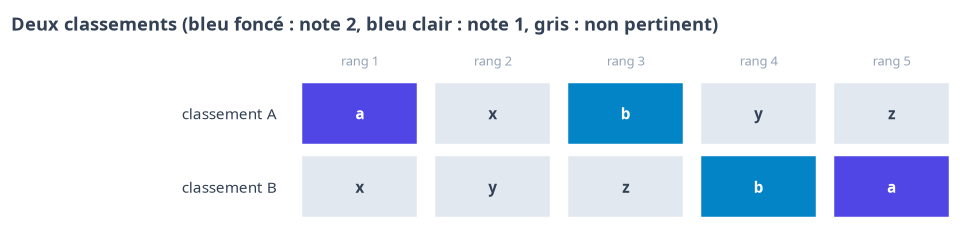

,P@5,R@5,RR,AP,NDCG@5
classement A,0.4,0.667,1.00,0.556,0.798
classement B,0.4,0.667,0.25,0.217,0.385


In [2]:
rel = {"a": 2, "b": 1, "c": 1}
classements = {"classement A": ["a", "x", "b", "y", "z"], "classement B": ["x", "y", "z", "b", "a"]}
fig, ax = plt.subplots(figsize=(9, 2.3))
couleur = {2: INDIGO, 1: SKY, 0: "#E2E8F0"}
for row, (nom, r) in enumerate(classements.items()):
    for i, dname in enumerate(r):
        g = rel.get(dname, 0)
        ax.add_patch(plt.Rectangle((i, -row - 0.4), 0.85, 0.8, color=couleur[g]))
        ax.text(i + 0.425, -row, dname, ha="center", va="center", color="white" if g else SLATE, fontweight="bold")
    ax.text(-0.2, -row, nom, ha="right", va="center", fontsize=10)
for i in range(5):
    ax.text(i + 0.425, 0.65, f"rang {i + 1}", ha="center", fontsize=8.5, color=GRAY)
ax.set_xlim(-2.2, 5); ax.set_ylim(-1.6, 1.0); ax.axis("off")
ax.set_title("Deux classements (bleu foncé : note 2, bleu clair : note 1, gris : non pertinent)")
plt.tight_layout(); plt.show()
pd.DataFrame({nom: {"P@5": c6.precision_at_k(r, rel, 5), "R@5": c6.recall_at_k(r, rel, 5),
                    "RR": c6.reciprocal_rank(r, rel), "AP": c6.average_precision(r, rel),
                    "NDCG@5": c6.ndcg_at_k(r, rel, 5)} for nom, r in classements.items()}).T.round(3)

La précision et le rappel ignorent l'ordre ; RR, AP et NDCG le prennent en compte. Pour un
RAG, l'ordre importe moins qu'en recherche Web (le livre le souligne dans *Reranking*) : un
document inclus dans le contexte est lu quelle que soit sa position, même si les modèles
exploitent mieux le début et la fin du contexte. Le rappel@k, lui, est crucial : un passage
absent du contexte est perdu.

> **À retenir.** Précision@k et rappel@k mesurent **quoi** est renvoyé ; MRR, MAP et NDCG
> mesurent aussi **dans quel ordre**. Le rappel exige une annotation exhaustive ; la
> précision peut être jugée par un modèle sur les seuls documents renvoyés.

## 2. Évaluer nos retrievers (section *Comparing retrieval algorithms*)

Appliquons ces métriques aux retrievers du cours 1 sur les 42 questions. Pour chaque
question, on garde les 20 premiers passages.

In [3]:
bm25 = c6.TermRetriever(TEXTS, IDS)
retrievers = {"TF-IDF": c6.TermRetriever(TEXTS, IDS, "tfidf"), "BM25": bm25,
              "dense EN": c6.DenseRetriever(TEXTS, IDS, llm.EMBED), "dense multi": c6.DenseRetriever(TEXTS, IDS, llm.EMBED_MULTI)}
dense = retrievers["dense multi"]
runs = {n: {q["qid"]: r.search(q["question"], 20) for q in Q} for n, r in retrievers.items()}
pd.DataFrame({n: c6.evaluate(r, k=5) for n, r in runs.items()}).T.round(3)

,P@5,R@5,Hit@5,MRR,NDCG@5
TF-IDF,0.195,0.905,0.929,0.764,0.785
BM25,0.195,0.905,0.929,0.784,0.803
dense EN,0.176,0.821,0.833,0.673,0.694
dense multi,0.210,0.964,0.976,0.836,0.864


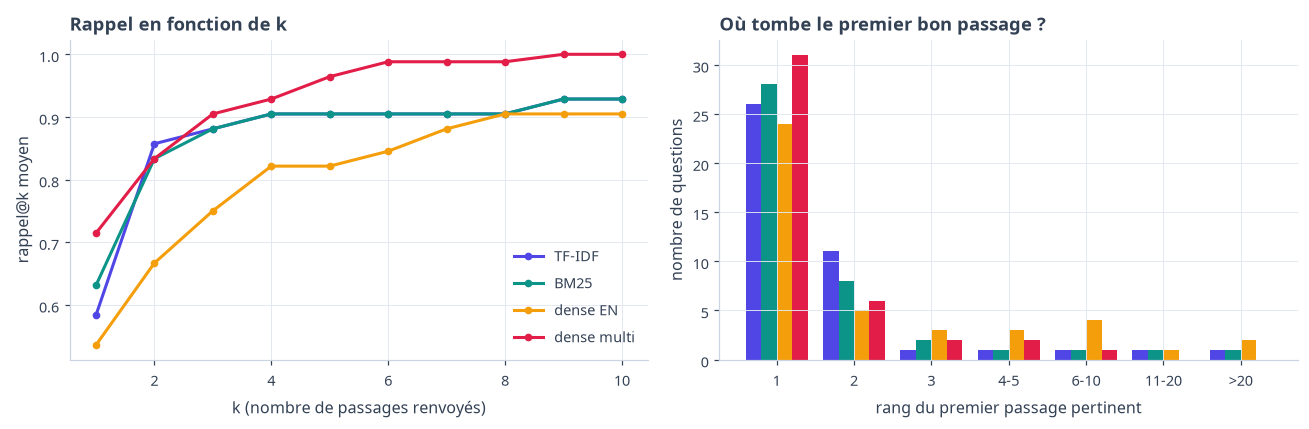

In [4]:
ks = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cols = dict(zip(runs, [INDIGO, TEAL, AMBER, ROSE]))
for n, r in runs.items():
    axes[0].plot(ks, [np.mean([c6.recall_at_k(r[q["qid"]], q["relevant"], k) for q in Q]) for k in ks],
                 marker="o", ms=4, color=cols[n], label=n)
axes[0].set_xlabel("k (nombre de passages renvoyés)"); axes[0].set_ylabel("rappel@k moyen")
axes[0].set_title("Rappel en fonction de k"); axes[0].legend()
rangs = {n: [next((i + 1 for i, d in enumerate(r[q["qid"]]) if d in q["relevant"]), 21) for q in Q] for n, r in runs.items()}
bins = [1, 2, 3, 4, 6, 11, 21, 22]
lab = ["1", "2", "3", "4-5", "6-10", "11-20", ">20"]
width = 0.2
for j, (n, rg) in enumerate(rangs.items()):
    h = np.histogram(rg, bins=bins)[0]
    axes[1].bar(np.arange(len(lab)) + (j - 1.5) * width, h, width, color=cols[n], label=n)
axes[1].set_xticks(range(len(lab))); axes[1].set_xticklabels(lab)
axes[1].set_xlabel("rang du premier passage pertinent"); axes[1].set_ylabel("nombre de questions")
axes[1].set_title("Où tombe le premier bon passage ?")
finish(fig); plt.show()

Avec $k = 5$, le modèle multilingue retrouve le bon passage pour presque toutes les questions,
BM25 pour un peu moins ; la précision@5 plafonne mécaniquement vers 0,2 car la plupart des
questions n'ont qu'un passage pertinent (au mieux 1/5). Le choix de $k$ est un compromis :
plus de passages augmente le rappel mais aussi le nombre de tokens envoyés au générateur (et
le bruit qu'il doit ignorer).

> **À retenir.** Toujours tracer le **rappel@k en fonction de k** : il dit combien de passages
> il faut envoyer au générateur pour ne pas perdre l'information.

## 3. Recherche hybride (section *Combining retrieval algorithms*)

Combiner recherche par termes et par embeddings s'appelle la **recherche hybride**. Deux
manières :

- **en cascade** : un retriever bon marché (BM25) présélectionne des candidats, un mécanisme
  plus précis et plus cher les reclasse (c'est déjà du *reranking*) ;
- **en parallèle** : plusieurs retrievers produisent chacun un classement, qu'on **fusionne**.

La **fusion par rang réciproque** (RRF, Cormack et al., 2009) n'utilise que les rangs :
$$\mathrm{RRF}(D) = \sum_{i=1}^{n} \frac{1}{k + r_i(D)},$$
où $r_i(D)$ est le rang de $D$ pour le retriever $i$ et $k$ une constante (typiquement 60) qui
évite la division par zéro et atténue l'écart entre les premiers rangs. Avantage décisif : pas
besoin de rendre comparables des scores BM25 (non bornés) et des cosinus (dans $[-1, 1]$).

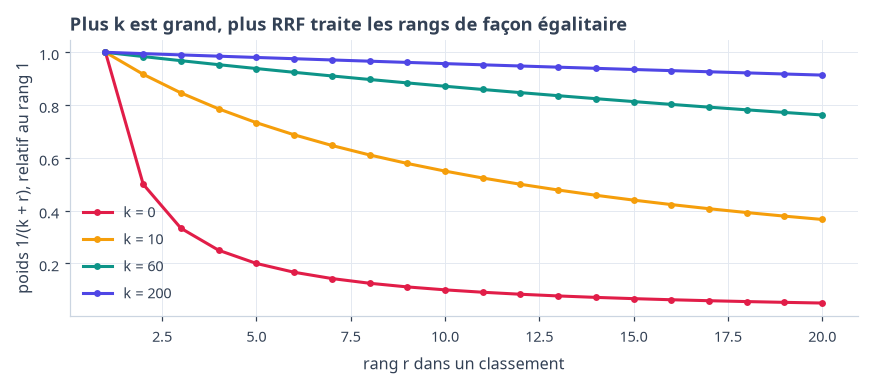

In [5]:
r_ = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(8, 3.6))
for k_, col in [(0, ROSE), (10, AMBER), (60, TEAL), (200, INDIGO)]:
    w = 1 / (k_ + r_)
    ax.plot(r_, w / w[0], marker="o", ms=3.5, color=col, label=f"k = {k_}")
ax.set_xlabel("rang r dans un classement"); ax.set_ylabel("poids 1/(k + r), relatif au rang 1")
ax.set_title("Plus k est grand, plus RRF traite les rangs de façon égalitaire")
ax.legend(); plt.tight_layout(); plt.show()

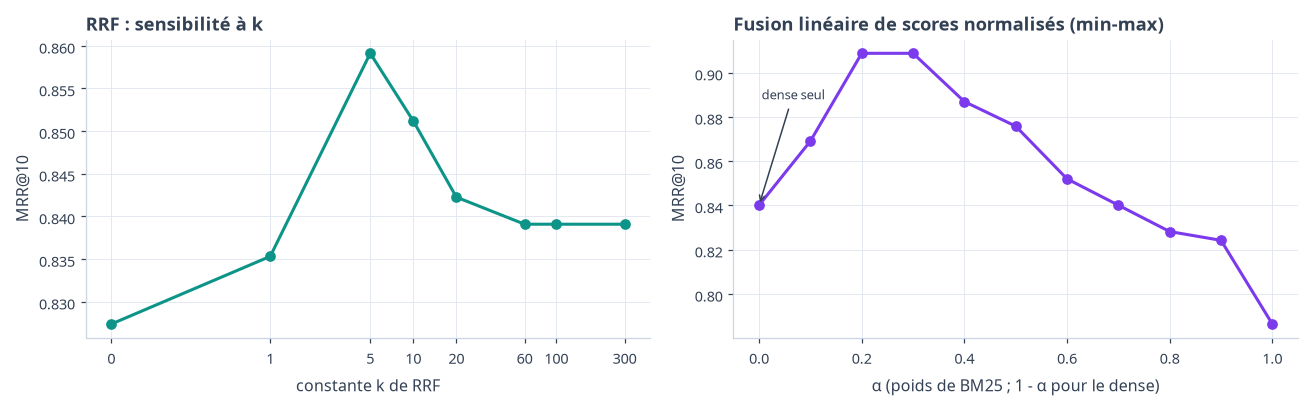

In [6]:
def hybride_rrf(k_=60, weights=None, depth=20):
    return {q["qid"]: [d for d, _ in c6.rrf([runs["BM25"][q["qid"]][:depth], runs["dense multi"][q["qid"]][:depth]], k_, weights)]
            for q in Q}

def hybride_lineaire(alpha):
    out = {}
    for q in Q:
        s = alpha * c6.minmax(bm25.scores(q["question"])) + (1 - alpha) * c6.minmax(dense.scores(q["question"]))
        out[q["qid"]] = c6.rank(s, IDS, 20)
    return out

def cascade(n_cand=10):
    out = {}
    for q in Q:
        cand = runs["BM25"][q["qid"]][:n_cand]
        s = dense.scores(q["question"])
        out[q["qid"]] = sorted(cand, key=lambda d_: -s[IDS.index(d_)])
    return out

ks_rrf = [0, 1, 5, 10, 20, 60, 100, 300]
alphas = np.linspace(0, 1, 11)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(ks_rrf, [c6.evaluate(hybride_rrf(k_), k=10)["MRR"] for k_ in ks_rrf], marker="o", color=TEAL)
axes[0].set_xscale("symlog", linthresh=1); axes[0].set_xticks(ks_rrf); axes[0].set_xticklabels(ks_rrf)
axes[0].set_xlabel("constante k de RRF"); axes[0].set_ylabel("MRR@10"); axes[0].set_title("RRF : sensibilité à k")
axes[1].plot(alphas, [c6.evaluate(hybride_lineaire(a), k=10)["MRR"] for a in alphas], marker="o", color=VIOLET)
axes[1].set_xlabel("α (poids de BM25 ; 1 - α pour le dense)"); axes[1].set_ylabel("MRR@10")
axes[1].set_title("Fusion linéaire de scores normalisés (min-max)")
for ax_, txt in [(axes[1], "dense seul"), ]:
    ax_.annotate(txt, (0, c6.evaluate(hybride_lineaire(0), k=10)["MRR"]), xytext=(0.05, 0.8), textcoords="axes fraction", fontsize=8.5,
                 arrowprops=dict(arrowstyle="->", color=SLATE))
finish(fig); plt.show()

In [7]:
variantes = {"BM25": runs["BM25"], "dense multi": runs["dense multi"], "RRF (k=60)": hybride_rrf(60),
             "linéaire (α=0,3)": hybride_lineaire(0.3), "cascade BM25 top-10 -> dense": cascade(10)}
tab = pd.DataFrame({n: c6.evaluate(r, k=5) for n, r in variantes.items()}).T
par_type = pd.DataFrame({n: c6.per_question(r, k=10).groupby("type")["RR"].mean() for n, r in variantes.items()}).T
pd.concat([tab[["R@5", "MRR", "NDCG@5"]], par_type.add_prefix("MRR ")], axis=1).round(3)

,R@5,MRR,NDCG@5,MRR ambigu,MRR lexical,MRR semantique
BM25,0.905,0.784,0.803,0.833,0.947,0.626
dense multi,0.964,0.836,0.864,0.833,0.870,0.812
RRF (k=60),0.929,0.832,0.841,1.000,0.947,0.712
"linéaire (α=0,3)",0.964,0.905,0.912,0.833,1.000,0.833
cascade BM25 top-10 -> dense,0.929,0.822,0.840,0.833,0.886,0.760


Lisons ce tableau avec honnêteté. RRF obtient le meilleur score sur les questions ambiguës et
lexicales, mais perd sur les questions sémantiques une partie de l'avance du dense : au total,
il fait jeu égal avec le dense, nettement mieux que BM25. La fusion **linéaire** avec
$\alpha = 0{,}3$ obtient le meilleur score global... mais $\alpha$ a été choisi **sur les
mêmes 42 questions** qui servent à l'évaluer : ce score est optimiste (sur-apprentissage du
réglage), et la courbe montre qu'un mauvais $\alpha$ coûte cher. RRF, lui, n'a rien à régler
(la courbe en $k$ est plate autour de 60) et n'a pas besoin de rendre les scores comparables.
La cascade est limitée par le rappel du premier étage : un passage que BM25 ne remonte pas dans
son top-10 ne peut pas être sauvé. Pour régler $\alpha$ proprement, il faudrait un jeu de
validation distinct du jeu de test (voir l'exercice 6.5).

> **À retenir.** **RRF** fusionne des classements sans calibrer les scores : $\sum_i 1/(k + r_i)$,
> avec $k \approx 60$. La recherche hybride combine la précision lexicale de BM25 et la
> souplesse sémantique des embeddings.

## 4. Stratégies de découpage (section *Chunking strategy*)

Jusqu'ici, un passage était un paragraphe rédigé à la main. En pratique, il faut **découper**
des documents de longueur quelconque. Options décrites par le livre :

- longueur fixe en **caractères**, **mots** ou **tokens** (le découpage en tokens du
  générateur facilite le dimensionnement mais oblige à réindexer si l'on change de modèle) ;
- unités linguistiques : **phrases**, **paragraphes** ;
- **récursif** : sections, puis paragraphes, puis phrases, jusqu'à passer sous la taille maximale ;
- avec **chevauchement** (*overlap*), pour qu'une information à cheval sur une frontière figure
  entière dans au moins un morceau (l'exemple du livre : « I left my wife » / « a note »).

Visualisons quatre découpages de la fiche de la boutique Minou Chic. La bande ambre marque
l'extrait qui répond à « Mon chat a un cou de 25 cm, quelle taille commander ? ».

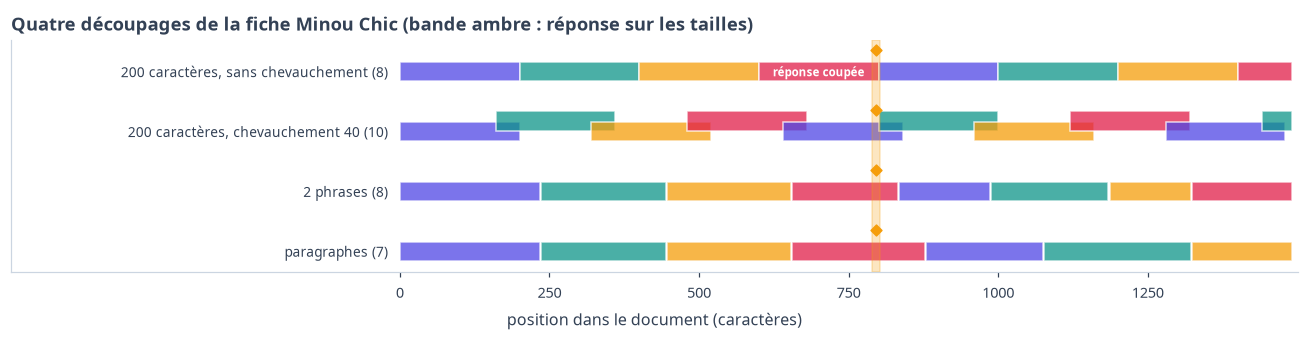

In [8]:
doc = next(d_ for d_ in c6.DOCUMENTS if d_["doc"] == "minou")
texte = c6.document_text(doc)
cle = next(q for q in Q if q["qid"] == "q34")["key"]
pos = texte.index(cle)

def bornes(chunks, text):
    out, start = [], 0
    for ch in chunks:
        i = text.find(ch[:30], max(start - len(ch), 0))
        i = start if i < 0 else i
        out.append((i, i + len(ch)))
        start = i + 1
    return out

decoupes = {"200 caractères, sans chevauchement": c6.chunk_chars(texte, 200),
            "200 caractères, chevauchement 40": c6.chunk_chars(texte, 200, 40),
            "2 phrases": c6.chunk_sentences(texte, 2),
            "paragraphes": c6.chunk_paragraphs(texte)}
fig, ax = plt.subplots(figsize=(12, 3.2))
for row, (nom, chs) in enumerate(decoupes.items()):
    for j, (a, b) in enumerate(bornes(chs, texte)):
        y = -row + (0.18 if (j % 2 and "chevauchement 40" in nom) else 0)
        ax.barh(y, b - a, left=a, height=0.32, color=COLORS[j % 4], alpha=0.75, edgecolor="white")
        cut = a <= pos < b and not (a <= pos + len(cle) <= b)
        if cut:
            ax.text((a + b) / 2, y, "réponse coupée", ha="center", va="center", fontsize=7.5, color="white", fontweight="bold")
    ax.text(-20, -row, f"{nom} ({len(chs)})", ha="right", va="center", fontsize=9)
ax.axvspan(pos, pos + len(cle), color=AMBER, alpha=0.25)
ax.scatter([pos + len(cle) / 2] * len(decoupes), -np.arange(len(decoupes)) + 0.36, marker="D", color=AMBER, zorder=5, s=25)
ax.set_xlim(-650, len(texte) + 10); ax.set_yticks([]); ax.set_xlabel("position dans le document (caractères)")
ax.set_xticks(np.arange(0, len(texte), 250))
ax.set_title("Quatre découpages de la fiche Minou Chic (bande ambre : réponse sur les tailles)")
ax.grid(False); plt.tight_layout(); plt.show()

Sans chevauchement, la coupe à 200 caractères tombe au milieu de « de 22 à 28 cm » : aucun
morceau ne contient la réponse entière. Avec 40 caractères de chevauchement, l'un des morceaux
la contient ; les découpages en phrases et en paragraphes la respectent par construction.

Mesurons l'effet du découpage sur la recherche. Un morceau est jugé pertinent s'il contient
**en entier** l'extrait-clé annoté pour la question (sinon, l'information est coupée ou
absente). On mesure, avec le retriever dense multilingue et $k = 3$ :
le **Hit@3** (au moins un morceau pertinent parmi les 3 premiers) et le **coût** en tokens des
3 morceaux envoyés au générateur, ainsi que la taille de l'index (nombre de morceaux).

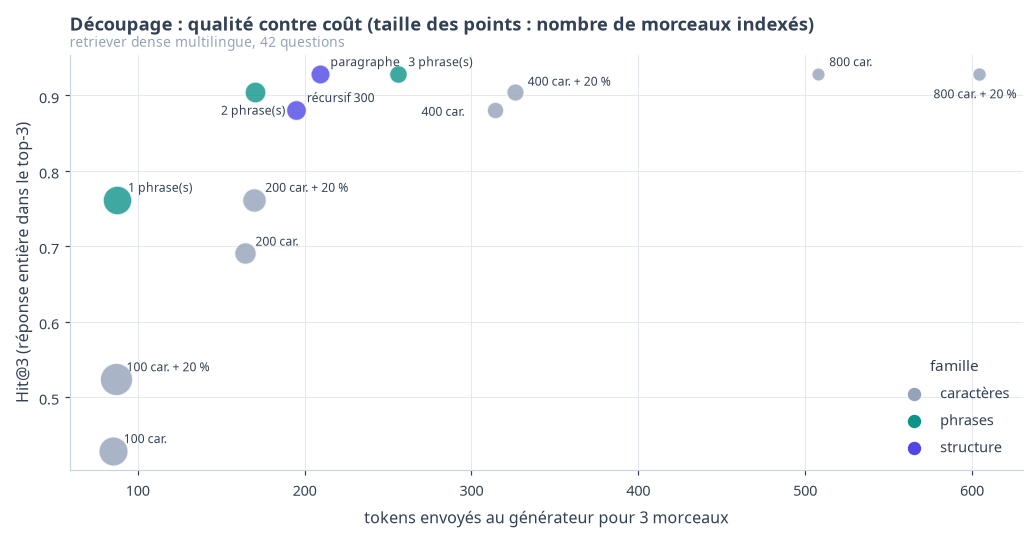

,stratégie,famille,morceaux,Hit@3,tokens envoyés (top-3)
0,100 car.,caractères,160,0.429,85.143
1,100 car. + 20 %,caractères,198,0.524,86.810
2,200 car.,caractères,84,0.690,164.095
3,200 car. + 20 %,caractères,102,0.762,169.952
4,400 car.,caractères,46,0.881,313.976
5,400 car. + 20 %,caractères,51,0.905,326.357
6,800 car.,caractères,26,0.929,507.976
7,800 car. + 20 %,caractères,28,0.929,604.357
8,1 phrase(s),phrases,154,0.762,87.762
9,2 phrase(s),phrases,78,0.905,170.000


In [9]:
strategies = {}
for s_ in [100, 200, 400, 800]:
    strategies[f"{s_} car."] = (lambda s_: lambda t: c6.chunk_chars(t, s_))(s_)
    strategies[f"{s_} car. + 20 %"] = (lambda s_: lambda t: c6.chunk_chars(t, s_, s_ // 5))(s_)
for n_ in [1, 2, 3]:
    strategies[f"{n_} phrase(s)"] = (lambda n_: lambda t: c6.chunk_sentences(t, n_))(n_)
strategies["paragraphe"] = c6.chunk_paragraphs
strategies["récursif 300"] = lambda t: c6.chunk_recursive(t, 300)

lignes = []
for nom, f in strategies.items():
    tx, ids, _ = c6.make_chunks(f)
    r = c6.DenseRetriever(tx, ids)
    t2 = dict(zip(ids, tx))
    hits, toks = [], []
    for q in Q:
        relc = c6.chunk_relevance(tx, ids, q["key"])
        top = r.search(q["question"], 3)
        hits.append(any(t in relc for t in top))
        toks.append(sum(ntok(t2[t]) for t in top))
    famille = "caractères" if "car." in nom else ("phrases" if "phrase" in nom else "structure")
    lignes.append({"stratégie": nom, "famille": famille, "morceaux": len(tx), "Hit@3": np.mean(hits),
                   "tokens envoyés (top-3)": np.mean(toks)})
chunk_df = pd.DataFrame(lignes)

fig, ax = plt.subplots(figsize=(9.5, 5))
fam_col = {"caractères": GRAY, "phrases": TEAL, "structure": INDIGO}
for _, row in chunk_df.iterrows():
    ax.scatter(row["tokens envoyés (top-3)"], row["Hit@3"], s=row["morceaux"] * 2.2 + 20,
               color=fam_col[row["famille"]], alpha=0.8, edgecolor="white", zorder=3)
    dx_, dy_ = {"400 car.": (-48, -4), "400 car. + 20 %": (8, 4), "800 car. + 20 %": (-30, -16), "2 phrase(s)": (-22, -15)}.get(row["stratégie"], (7, 5))
    ax.annotate(row["stratégie"], (row["tokens envoyés (top-3)"], row["Hit@3"]), xytext=(dx_, dy_),
                textcoords="offset points", fontsize=8)
for fam, col in fam_col.items():
    ax.scatter([], [], color=col, s=60, label=fam)
ax.set_xlabel("tokens envoyés au générateur pour 3 morceaux")
ax.set_ylabel("Hit@3 (réponse entière dans le top-3)")
ax.set_title("Découpage : qualité contre coût (taille des points : nombre de morceaux indexés)", pad=16)
subtitle(ax, "retriever dense multilingue, 42 questions")
ax.legend(title="famille", loc="lower right"); plt.tight_layout(); plt.show()
chunk_df.round(3)

Trois enseignements, cohérents avec le livre :

1. **Les petits morceaux perdent de l'information** : à 100 caractères, l'extrait-clé est
   souvent coupé ou séparé de ce qui permet de le retrouver ; le Hit@3 s'effondre, et l'index
   compte plus de morceaux (plus d'embeddings à calculer et à stocker).
2. **Le chevauchement aide** les découpages à longueur fixe, pour un coût modeste en index.
3. **Respecter la structure** (phrases, paragraphes, récursif) donne, à coût en tokens égal,
   une meilleure qualité qu'une coupe aveugle en caractères. Les gros morceaux (800
   caractères) atteignent un bon Hit@3 mais envoient beaucoup plus de tokens, souvent inutiles.

Il n'existe pas de taille universelle : il faut mesurer sur ses propres données, comme ici.

> **À retenir.** Le découpage arbitre entre **précision** (petits morceaux ciblés, plus
> nombreux) et **complétude** (gros morceaux, plus de tokens). Préférer les frontières
> naturelles du texte et un léger chevauchement ; ne jamais dépasser la limite de contexte du
> modèle d'embedding.

## 5. Reranking (section *Reranking*)

Le premier classement peut être affiné par un **reranker** plus précis mais plus cher, appliqué
aux seuls candidats (ici les 20 premiers de la fusion RRF). Le plus courant est le
**cross-encoder** : au lieu d'encoder question et passage séparément (bi-encodeur, comme nos
embeddings), il lit la paire **concaténée** et produit directement un score de pertinence.
Toutes les couches d'attention voient à la fois la question et le passage : c'est plus précis,
mais il faut un passage complet dans le réseau **par candidat et par requête** (impossible à
précalculer). On compare avec un reranking par LLM : Qwen2.5-0.5B lit la paire et on prend la
probabilité qu'il réponde « Oui » à « ce passage contient-il la réponse ? ».

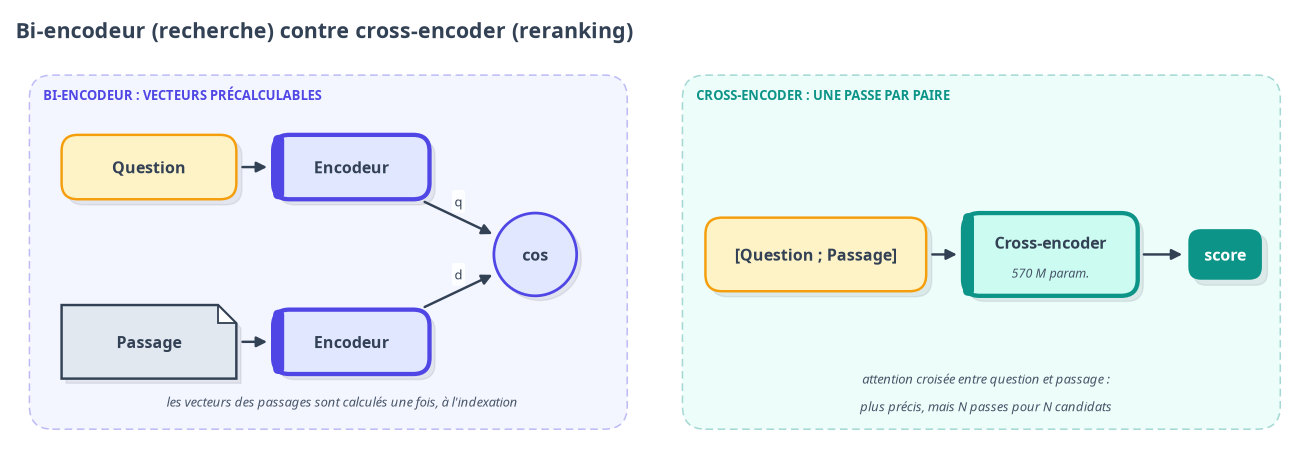

In [10]:
d = Diagram(14, 4.15, title="Bi-encodeur (recherche) contre cross-encoder (reranking)")
d.group(0.2, 0.15, 6.7, 4.0, "bi-encodeur : vecteurs précalculables", color=INDIGO)
d.group(7.3, 0.15, 13.8, 4.0, "cross-encoder : une passe par paire", color=TEAL)
d.box("q1", 1.5, 3.0, "Question", color=AMBER, w=1.9, h=0.7)
d.box("p1", 1.5, 1.1, "Passage", color=SLATE, kind="doc", w=1.9, h=0.8)
d.box("e1", 3.7, 3.0, "Encodeur", color=INDIGO, kind="model", w=1.7, h=0.7)
d.box("e2", 3.7, 1.1, "Encodeur", color=INDIGO, kind="model", w=1.7, h=0.7)
d.box("cos", 5.7, 2.05, "cos", color=INDIGO, kind="circle", w=0.9)
d.arrow("q1", "e1"); d.arrow("p1", "e2"); d.arrow("e1", "cos", "q"); d.arrow("e2", "cos", "d")
d.box("pair", 8.75, 2.05, "[Question ; Passage]", color=AMBER, w=2.4, h=0.8)
d.box("ce", 11.3, 2.05, "Cross-encoder", sub="570 M param.", color=TEAL, kind="model", w=1.9)
d.box("sc", 13.2, 2.05, "score", color=TEAL, kind="tag", w=0.8, h=0.55)
d.arrow("pair", "ce"); d.arrow("ce", "sc")
d.note(3.6, 0.45, "les vecteurs des passages sont calculés une fois, à l'indexation", fontsize=8.5)
d.note(10.6, 0.7, "attention croisée entre question et passage :", fontsize=8.5)
d.note(10.6, 0.4, "plus précis, mais N passes pour N candidats", fontsize=8.5)
d.show()

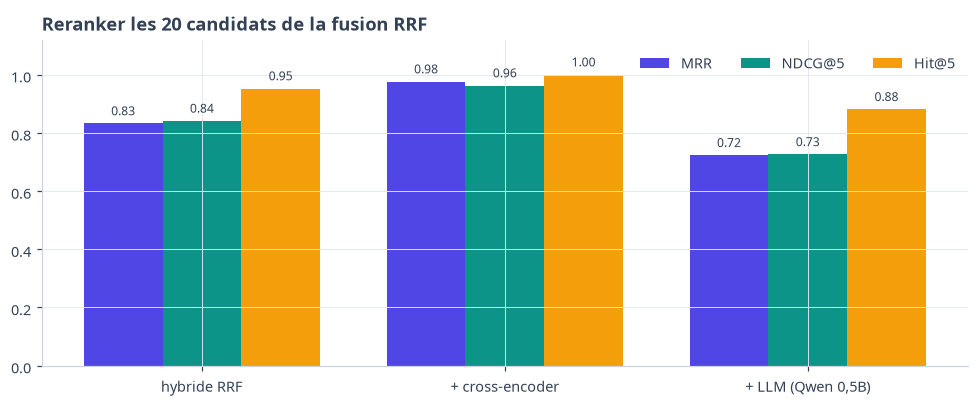

,P@5,R@5,Hit@5,MRR,NDCG@5,latence de reranking (ms / requête)
hybride RRF,0.200,0.929,0.952,0.832,0.841,0.000
+ cross-encoder,0.214,0.988,1.000,0.976,0.963,2756.876
"+ LLM (Qwen 0,5B)",0.181,0.845,0.881,0.723,0.726,322.667


In [11]:
hyb = hybride_rrf(60)
cand = {q["qid"]: hyb[q["qid"]][:20] for q in Q}
t = time.perf_counter()
run_ce = {}
for q in Q:
    s = c6.cross_encoder_scores(q["question"], [TXT[d_] for d_ in cand[q["qid"]]])
    run_ce[q["qid"]] = [cand[q["qid"]][i] for i in np.argsort(-s, kind="stable")]
t_ce = (time.perf_counter() - t) / len(Q)
t = time.perf_counter()
run_llm = {}
for q in Q:
    s = c6.llm_rerank_scores(q["question"], [TXT[d_] for d_ in cand[q["qid"]]])
    run_llm[q["qid"]] = [cand[q["qid"]][i] for i in np.argsort(-s, kind="stable")]
t_llm = (time.perf_counter() - t) / len(Q)
rr_tab = pd.DataFrame({"hybride RRF": c6.evaluate(cand, k=5), "+ cross-encoder": c6.evaluate(run_ce, k=5),
                       "+ LLM (Qwen 0,5B)": c6.evaluate(run_llm, k=5)}).T
rr_tab["latence de reranking (ms / requête)"] = [0, t_ce * 1000, t_llm * 1000]

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(3)
for j, (m, col) in enumerate([("MRR", INDIGO), ("NDCG@5", TEAL), ("Hit@5", AMBER)]):
    ax.bar(x + (j - 1) * 0.26, rr_tab[m], 0.26, color=col, label=m)
annotate_bars(ax, "{:.2f}", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(rr_tab.index); ax.set_ylim(0, 1.12)
ax.set_title("Reranker les 20 candidats de la fusion RRF"); ax.legend(ncol=3, loc="upper right")
plt.tight_layout(); plt.show()
rr_tab.round(3)

Le cross-encoder multilingue (`BAAI/bge-reranker-v2-m3`) place le bon passage en tête pour
presque toutes les questions : c'est le gain le plus net du notebook, pour quelques
millisecondes par candidat. Le reranking par Qwen2.5-0.5B, à l'inverse, **dégrade** le
classement : un petit modèle généraliste est un mauvais juge de pertinence, alors qu'un modèle
de taille comparable **spécialisé** pour la tâche excelle. Un LLM bien plus gros ferait mieux,
mais coûterait bien plus cher par candidat. Voyons un exemple corrigé par le cross-encoder.

In [12]:
exemples = [q for q in Q if cand[q["qid"]][0] not in q["relevant"] and run_ce[q["qid"]][0] in q["relevant"]][:4]
pd.DataFrame([{"question": q["question"], "top-1 hybride": cand[q["qid"]][0], "top-1 après cross-encoder": run_ce[q["qid"]][0],
               "pertinent": ", ".join(q["relevant"])} for q in exemples])

,question,top-1 hybride,top-1 après cross-encoder,pertinent
0,"Mon thermostat affiche que les piles sont faibles, que faire ?",thermo-1,thermo-5,thermo-5
1,Le thermostat fonctionne-t-il avec un réseau 5 GHz ?,thermo-1,thermo-3,thermo-3
2,Comment remettre l'appareil Domotik dans son état d'origine avant de le vendre ?,minou-6,thermo-7,thermo-7
3,Quelle température le thermostat maintient-il quand je pars en congé ?,thermo-1,thermo-6,thermo-6


Le livre mentionne aussi le reranking **temporel** (favoriser les documents récents : actualités,
courriels, finance) et rappelle que pour un RAG, l'enjeu principal est de **réduire** le nombre
de passages (pour tenir dans le contexte et baisser le coût) sans perdre le bon.

> **À retenir.** Schéma classique : retriever rapide sur tout le corpus (top-50 ou top-100),
> puis **cross-encoder** sur ces candidats, puis top-5 au générateur. Un juge LLM n'est utile
> que s'il est assez fort ; un petit modèle spécialisé bat souvent un petit modèle généraliste.

## 6. Réécriture de requête (section *Query rewriting*)

Dans une conversation, la dernière question n'a souvent de sens qu'avec ce qui précède («
Peut-on la renouveler ? »). Utilisée telle quelle, elle ramène des passages hors sujet. La
**réécriture** (*query reformulation*) produit une requête autonome, ici par un LLM guidé par
une consigne système et deux exemples. On compare cinq requêtes : la question brute, la
question précédée du message précédent de l'utilisateur (heuristique sans modèle), la
réécriture par Qwen2.5-0.5B, la réécriture par Qwen2.5-1.5B (exécuté sur CPU pour épargner le
GPU partagé) et la réécriture idéale rédigée à la main.

Qwen2.5-1.5B sur CPU : 5 s pour 8 réécritures


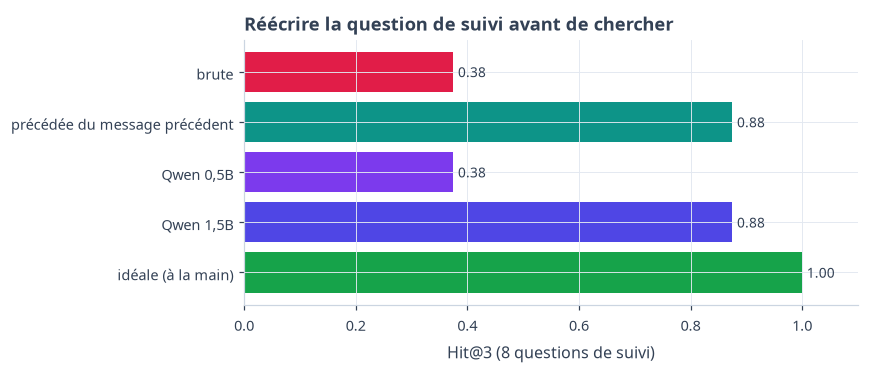

,question brute,"réécriture 0,5B","réécriture 1,5B"
0,Peut-on la renouveler ?,Peut-on la retenir ?,Peut-on prolonger la période d'essai chez Calypso ?
1,Quelle est sa particularité la plus célèbre ?,Quelle est sa particularité la plus célèbre ?,Quelle est sa particularité la plus célèbre sur Jupiter ?
2,Comment savoir quel programme est en cause ?,Comment savoir quel programme est en cause ?,Comment puis-je identifier le programme qui utilise le port actuellement ?
3,Et quelles herbes ajoute-t-on à la fin ?,Et quelle herbe fait-elle partie de la finale ?,Et quelle sont les herbes ajoutées à la fin de la soupe de phở ?
4,Et à partir de quand y a-t-on droit ?,Et à partir de quand y a-t-on droit ?,Et à partir de quand on a droit au télétravail chez Calypso ?
5,Je peux le rendre s'il ne va pas à mon chat ?,Je peux le rendre si il ne va pas à mon chat ?,Je peux le rendre si ce n'est pas à mon chat ?
6,À quelle distance faut-il les espacer ?,À quelle distance faut-il les espacer ?,À quelle distance faut-il planter les tomates ?
7,Combien de temps est-il couvert en cas de panne ?,Combien de temps est-il couvert en cas de panne ?,Combien de temps est couvert en cas de panne le thermostat Thermo-X200 de la société Domotik ?


In [13]:
SYS_REECRITURE = ("Tu reformules des questions. Tu ne réponds jamais à la question : tu la réécris pour qu'elle "
                  "soit compréhensible seule, en remplaçant les pronoms (il, elle, la, les, sa, ça) par le nom qu'ils désignent.")
EXEMPLES = [("Utilisateur : Quelle est la capitale de l'Italie ?\nAssistant : Rome.", "Combien d'habitants a-t-elle ?",
             "Combien d'habitants a Rome ?"),
            ("Utilisateur : Le vélo électrique Volta est-il pliable ?\nAssistant : Oui, il se plie en deux.", "Quel est son poids ?",
             "Quel est le poids du vélo électrique Volta ?")]
fmt_h = lambda c: "\n".join(("Utilisateur : " if r_ == "user" else "Assistant : ") + m for r_, m in c["history"])  # noqa: E731

def messages_reecriture(c):
    msgs = [{"role": "system", "content": SYS_REECRITURE}]
    for h, f, rep in EXEMPLES:
        msgs += [{"role": "user", "content": f"Conversation :\n{h}\nQuestion à réécrire : {f}"}, {"role": "assistant", "content": rep}]
    return msgs + [{"role": "user", "content": f"Conversation :\n{fmt_h(c)}\nQuestion à réécrire : {c['followup']}"}]

conv_msgs = [messages_reecriture(c) for c in c6.CONVERSATIONS]
reecrites = [r_.split("\n")[0].strip() for r_ in c6.generate_batch(conv_msgs, max_new_tokens=40)]
t = time.perf_counter()
reecrites_15 = [r_.split("\n")[0].strip() for r_ in c6.generate_batch(conv_msgs, model_id=llm.MEDIUM, max_new_tokens=40, device="cpu")]
print(f"Qwen2.5-1.5B sur CPU : {time.perf_counter() - t:.0f} s pour 8 réécritures")

def hit3(query, relevant):
    top = [d_ for d_, _ in c6.rrf([bm25.search(query, 10), dense.search(query, 10)])][:3]
    return float(any(t_ in relevant for t_ in top))

lig = []
for c, rw, rw15 in zip(c6.CONVERSATIONS, reecrites, reecrites_15):
    lig.append({"question brute": c["followup"], "réécriture 0,5B": rw, "réécriture 1,5B": rw15,
                "brute": hit3(c["followup"], c["relevant"]),
                "précédée du message précédent": hit3(c["history"][0][1] + " " + c["followup"], c["relevant"]),
                "Qwen 0,5B": hit3(rw, c["relevant"]), "Qwen 1,5B": hit3(rw15, c["relevant"]),
                "idéale (à la main)": hit3(c["gold"], c["relevant"])})
rw_df = pd.DataFrame(lig)
scores = rw_df[["brute", "précédée du message précédent", "Qwen 0,5B", "Qwen 1,5B", "idéale (à la main)"]].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(scores.index[::-1], scores.values[::-1], color=[GREEN, INDIGO, VIOLET, TEAL, ROSE])
annotate_bars(ax, "{:.2f}")
ax.set_xlim(0, 1.1); ax.set_xlabel("Hit@3 (8 questions de suivi)")
ax.set_title("Réécrire la question de suivi avant de chercher")
plt.tight_layout(); plt.show()
rw_df[["question brute", "réécriture 0,5B", "réécriture 1,5B"]]

Les questions brutes échouent dès qu'elles ne contiennent plus de mot discriminant (« Peut-on
la renouveler ? »). Qwen2.5-0.5B recopie presque toujours la question sans résoudre les
pronoms (ou la déforme) : il n'apporte rien. Qwen2.5-1.5B remplace correctement les pronoms dans
la plupart des cas et se rapproche de la réécriture idéale : la réécriture est une tâche de
compréhension qui demande un modèle un peu plus capable. L'heuristique gratuite « concaténer le
message précédent » est un concurrent sérieux sur ces exemples courts, mais elle dégénère dans
les longues conversations (quel message concaténer ?). Le livre signale un piège plus profond : pour « Et sa femme ? », il faut
parfois interroger une base pour **résoudre l'identité** ; si l'information manque, le
réécrivain doit le dire au lieu d'inventer un nom.

> **À retenir.** Toute question de suivi doit être rendue **autonome** avant la recherche
> (réécriture par un modèle ou heuristique). Mesurer : un réécrivain trop faible peut
> dégrader la requête.

## 7. Recherche contextuelle (section *Contextual retrieval*)

Un morceau isolé perd souvent son contexte : « Il est garanti trois ans » ne dit pas **quel**
produit. La recherche contextuelle **augmente chaque morceau** avant de l'indexer : métadonnées
(titre, mots-clés, entités, questions auxquelles il répond) ou, comme Anthropic (2024), un
court contexte de 50 à 100 tokens **généré par un LLM** qui situe le morceau dans son document.

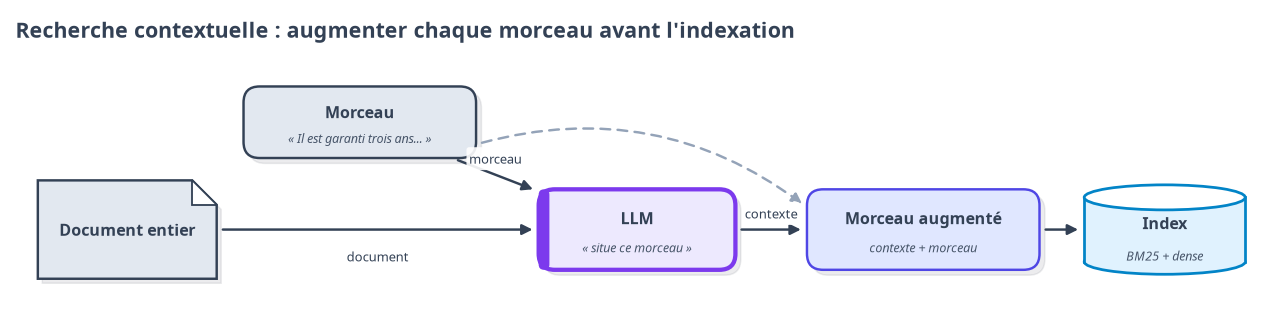

In [14]:
d = Diagram(14, 2.9, title="Recherche contextuelle : augmenter chaque morceau avant l'indexation")
d.box("doc", 1.3, 1.0, "Document entier", color=SLATE, kind="doc", w=2.0, h=1.1)
d.box("ch", 3.9, 2.2, "Morceau", sub="« Il est garanti trois ans... »", color=SLATE, w=2.6, h=0.8)
d.box("llm", 7.0, 1.0, "LLM", sub="« situe ce morceau »", color=VIOLET, kind="model", w=2.2)
d.box("aug", 10.2, 1.0, "Morceau augmenté", sub="contexte + morceau", color=INDIGO, w=2.6)
d.box("idx", 12.9, 1.0, "Index", sub="BM25 + dense", color=SKY, kind="db", w=1.8, h=1.0)
d.arrow("doc", "llm", "document", label_offset=(0, -0.3)); d.arrow("ch", "llm", "morceau")
d.arrow("llm", "aug", "contexte"); d.arrow("aug", "idx")
d.arrow("ch", "aug", style="dashed", rad=-0.25, color=GRAY)
d.show()

Expérience : on découpe les documents **phrase par phrase** (154 morceaux, beaucoup sans le
nom du produit ou de l'entreprise), puis on compare quatre index : morceau brut, titre du
document + morceau, contexte généré par Qwen + morceau, et titre + contexte + morceau. Le prompt
de Qwen reprend l'idée de celui d'Anthropic (document entre balises, morceau, consigne de
répondre seulement par le contexte), traduit et reformulé.

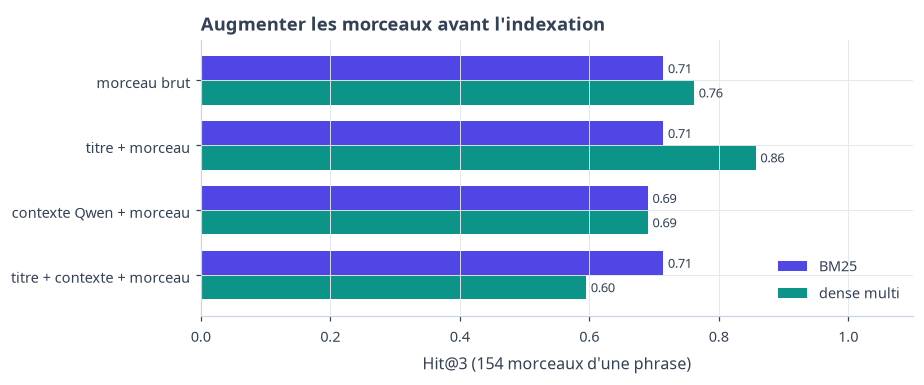

Génération de 154 contextes par Qwen : 10 s


,morceau,contexte généré par Qwen
0,Il mesure la température toutes les trente secondes et ajuste le chauffage pièce par pièce.,L'extraction mentionnée est un exemple de texte d'un document lié à un produit spécifique. Cela pourrait ê...
1,"Son écran tactile de 3,5 pouces affiche la consigne et la consommation du jour.","L'extrait mentionne l'utilisation d'un thermostat connecté pour réguler le chauffage de maison, fournissan..."
2,"Avant l'installation, coupez l'alimentation électrique au disjoncteur.","Lors de l'installation, il faut couper l'alimentation électrique au disjoncteur pour assurer une bonne fon..."
3,Elle remplace les réseaux récurrents par un mécanisme d'attention qui traite tous les tokens d'une séquenc...,Attention: Transformer est une architecture de langage qui utilise l'attention pour traiter plus de tokens...
4,Elle est à la base de la plupart des grands modèles de langage actuels.,"Attention, cette architecture Transformer est essentielle pour la génération de textes naturels, notamment..."


In [15]:
tx, ids, own = c6.make_chunks(lambda t_: c6.chunk_sentences(t_, 1))
titre = {d_["doc"]: d_["title"] for d_ in c6.DOCUMENTS}
plein = {d_["doc"]: c6.document_text(d_) for d_ in c6.DOCUMENTS}
PROMPT_CTX = ("<document>\n{doc}\n</document>\n\nVoici un extrait de ce document :\n<extrait>\n{ch}\n</extrait>\n\n"
              "Donne un contexte court (une phrase) qui situe cet extrait dans le document, afin d'améliorer "
              "sa recherche. Réponds uniquement par ce contexte.")
t = time.perf_counter()
ctx = c6.generate_batch([PROMPT_CTX.format(doc=plein[o], ch=c_) for c_, o in zip(tx, own)], max_new_tokens=40, batch_size=24)
t_ctx = time.perf_counter() - t
versions = {"morceau brut": tx, "titre + morceau": [f"{titre[o]}. {c_}" for c_, o in zip(tx, own)],
            "contexte Qwen + morceau": [f"{x_} {c_}" for c_, x_ in zip(tx, ctx)],
            "titre + contexte + morceau": [f"{titre[o]}. {x_} {c_}" for c_, x_, o in zip(tx, ctx, own)]}
res_ctx = {}
for nom, v in versions.items():
    res_ctx[nom] = {}
    for meth, R in [("BM25", c6.TermRetriever), ("dense multi", c6.DenseRetriever)]:
        r = R(v, ids)
        res_ctx[nom][meth] = np.mean([any(t_ in c6.chunk_relevance(tx, ids, q["key"]) for t_ in r.search(q["question"], 3)) for q in Q])
res_ctx = pd.DataFrame(res_ctx).T
ax = res_ctx.plot.barh(figsize=(8.5, 3.6), color=[INDIGO, TEAL], width=0.75)
annotate_bars(ax, "{:.2f}", fontsize=8.5)
ax.invert_yaxis(); ax.set_xlim(0, 1.1); ax.set_xlabel("Hit@3 (154 morceaux d'une phrase)")
ax.set_title("Augmenter les morceaux avant l'indexation"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"Génération de {len(tx)} contextes par Qwen : {t_ctx:.0f} s")
pd.DataFrame({"morceau": tx[1:4] + tx[60:62], "contexte généré par Qwen": ctx[1:4] + ctx[60:62]})

Ajouter le **titre du document** améliore nettement la recherche dense : le morceau « Il est
garanti trois ans » devient trouvable par « garantie du Thermo-X200 ». Les contextes générés
par Qwen2.5-0.5B, eux, sont génériques (« L'extrait mentionne... »), parfois inexacts, et
**diluent** le morceau : ils n'aident pas, voire nuisent. Anthropic utilisait un modèle bien
plus capable ; avec un petit modèle, une métadonnée fiable (titre, section, entités extraites
automatiquement) est un meilleur investissement. Notez aussi le coût : un appel de LLM par
morceau à l'indexation (atténué en pratique par la mise en cache du document dans le prompt).

> **À retenir.** Un morceau doit porter son contexte : titre, section, mots-clés, questions
> qu'il résout, ou contexte généré. Vérifier par la mesure que l'augmentation aide : un
> contexte de mauvaise qualité ajoute du bruit.

## 8. Choisir une solution de recherche (encadré *Evaluating Retrieval Solutions*)

Au-delà de la qualité mesurée ci-dessus, le livre liste les questions à poser avant d'adopter
une base vectorielle ou un moteur de recherche :

| Critère | Question à poser |
|---|---|
| Mécanismes | Recherche hybride ? Quels modèles d'embedding et index ANN (HNSW, IVF, PQ) ? |
| Passage à l'échelle | Volume de données et trafic de requêtes supportés ? Adapté à vos pics ? |
| Indexation | Temps pour indexer vos données ? Ajouts et suppressions en masse ? |
| Latence | Latence de requête pour chaque algorithme ? |
| Coût | Facturation au volume de vecteurs ou au nombre de requêtes ? |
| Entreprise | Contrôle d'accès, conformité, séparation des plans de données et de contrôle |

On évalue enfin le système **composant par composant** (recherche, embeddings) et **de bout en
bout** (qualité des réponses finales), ce que fait le cours 3.

> **À retenir.** Une solution de recherche se choisit sur la qualité **et** sur l'indexation,
> la latence, l'échelle et le coût ; on l'évalue par composant et de bout en bout.

## Synthèse

- **Métriques** : précision@k et rappel@k (quoi), MRR, MAP et NDCG (dans quel ordre) ; le
  rappel@k en fonction de k dimensionne le nombre de passages à envoyer.
- **Hybride** : RRF fusionne des classements sans calibrer de scores et se montre robuste à
  sa constante ; la cascade dépend du rappel du premier étage.
- **Découpage** : les petits morceaux coupent l'information, les gros coûtent des tokens ; les
  frontières naturelles et un léger chevauchement donnent le meilleur compromis.
- **Reranking** : un cross-encoder spécialisé apporte le gain le plus net ; un petit LLM
  généraliste est un mauvais juge.
- **Réécriture** et **recherche contextuelle** : rendre la requête et les morceaux autonomes ;
  toujours vérifier par la mesure, car un modèle trop faible peut dégrader le résultat.

**Liens.** Évaluation et juges IA : chapitres 3 et 4. Prompt caching (pour la recherche
contextuelle à grande échelle) : chapitre 9. Le cours 3 branche ces retrievers sur un
générateur.

In [16]:
c6.free_models()